# Progetto di Image Restoration con Analisi in Fourier

Obiettivo:
- analizzare il rumore periodico tramite spettro della trasformata di Fourier;
- restaurare le immagini degradate;
- salvare le immagini restaurate in una cartella dedicata;
- generare `submission.csv` con immagini codificate in base64.

## Metriche di valutazione (specifica)
La challenge usa, per ogni immagine $i$:

- $p_i = \mathrm{PSNR}(\text{restored}_i, \text{original}_i)$
- $s_i = \mathrm{SSIM}(\text{restored}_i, \text{original}_i)$

Punteggio medio:

$$
\text{score} = \frac{1}{N}\sum_i s_i\,p_i
$$

In assenza delle immagini originali nel dataset locale, qui si esegue una stima non supervisionata basata su analisi spettrale e qualità percettiva.

In [3]:
import os
import base64
from pathlib import Path
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# Root directory robust to local run and Kaggle run
if Path('/kaggle/input').exists():
    ROOT_DIR = Path('/kaggle/input/eliva-26-image-restoration')
else:
    ROOT_DIR = Path.cwd()

DATA_DIR = ROOT_DIR / 'data26'
OUTPUT_DIR = ROOT_DIR / 'restored_images'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('ROOT_DIR:', ROOT_DIR)
print('DATA_DIR:', DATA_DIR)
print('OUTPUT_DIR:', OUTPUT_DIR)

patterns = ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']
image_paths = sorted({p for pat in patterns for p in glob(str(DATA_DIR / pat))})
print('Numero immagini trovate:', len(image_paths))
print('Prime immagini:', [Path(p).name for p in image_paths[:5]])

ROOT_DIR: \\wsl$\Ubuntu\ELIVA\Image_Restoration
DATA_DIR: \\wsl$\Ubuntu\ELIVA\Image_Restoration\data26
OUTPUT_DIR: \\wsl$\Ubuntu\ELIVA\Image_Restoration\restored_images
Numero immagini trovate: 15
Prime immagini: ['img1.jpg', 'img10.jpg', 'img11.jpg', 'img12.jpg', 'img13.jpg']


In [4]:
def encode_img(img):
    ok, buffer = cv2.imencode('.jpg', img)
    if not ok:
        raise ValueError('Impossibile codificare l\'immagine in JPEG')
    return base64.b64encode(buffer).decode('utf-8')


def decode_img_from_b64(txt):
    arr = np.frombuffer(base64.b64decode(txt), dtype=np.uint8)
    img = cv2.imdecode(arr, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError('Impossibile decodificare l\'immagine base64')
    return img


def show_bgr(ax, img, title=''):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')

In [5]:
def fft2_centered(gray_float):
    F = np.fft.fft2(gray_float)
    return np.fft.fftshift(F)


def ifft2_centered(Fc):
    return np.fft.ifft2(np.fft.ifftshift(Fc)).real


def magnitude_spectrum(Fc):
    return np.log1p(np.abs(Fc))


def radial_profile(img2d):
    h, w = img2d.shape
    cy, cx = h // 2, w // 2
    y, x = np.indices((h, w))
    r = np.sqrt((x - cx) ** 2 + (y - cy) ** 2).astype(np.int32)
    tbin = np.bincount(r.ravel(), img2d.ravel())
    nr = np.bincount(r.ravel())
    return tbin / np.maximum(nr, 1)


def smooth_1d(v, win):
    win = int(max(3, win))
    if win % 2 == 0:
        win += 1
    kernel = np.ones(win, dtype=np.float32) / win
    pad = win // 2
    vp = np.pad(v.astype(np.float32), (pad, pad), mode='reflect')
    return np.convolve(vp, kernel, mode='valid')


def robust_zscore(v):
    med = np.median(v)
    mad = np.median(np.abs(v - med)) + 1e-8
    return 0.6745 * (v - med) / mad


def select_peaks_1d(score, center_idx, center_radius=16, threshold=7.5, max_peaks=24, min_spacing=6):
    idx = np.arange(score.size)
    valid = np.abs(idx - center_idx) > center_radius
    cand = np.where((score > threshold) & valid)[0]
    if cand.size == 0:
        return []

    order = cand[np.argsort(score[cand])[::-1]]
    chosen = []
    for p in order:
        if len(chosen) >= max_peaks:
            break
        if all(abs(p - q) >= min_spacing for q in chosen):
            chosen.append(int(p))

    sym = set()
    for p in chosen:
        q = int(2 * center_idx - p)
        if 0 <= q < score.size:
            sym.add(int(p))
            sym.add(int(q))
    return sorted(sym)


def detect_axis_peaks(Fc, center_radius=16, z_threshold=7.5, max_peaks_per_axis=24, min_spacing=6):
    mag_log = magnitude_spectrum(Fc)
    h, w = mag_log.shape
    cy, cx = h // 2, w // 2

    prof_x = mag_log[cy, :].copy()
    prof_y = mag_log[:, cx].copy()

    prof_x[max(0, cx - center_radius): min(w, cx + center_radius + 1)] = np.median(prof_x)
    prof_y[max(0, cy - center_radius): min(h, cy + center_radius + 1)] = np.median(prof_y)

    baseline_x = smooth_1d(prof_x, max(9, w // 35))
    baseline_y = smooth_1d(prof_y, max(9, h // 35))

    score_x = robust_zscore(prof_x - baseline_x)
    score_y = robust_zscore(prof_y - baseline_y)

    x_peaks = select_peaks_1d(
        score_x,
        center_idx=cx,
        center_radius=center_radius,
        threshold=z_threshold,
        max_peaks=max_peaks_per_axis,
        min_spacing=min_spacing,
    )
    y_peaks = select_peaks_1d(
        score_y,
        center_idx=cy,
        center_radius=center_radius,
        threshold=z_threshold,
        max_peaks=max_peaks_per_axis,
        min_spacing=min_spacing,
    )

    return x_peaks, y_peaks, score_x, score_y


def detect_offaxis_peaks(Fc, center_radius=18, percentile=99.985, max_peaks=26, min_sep=10):
    mag = np.abs(Fc)
    h, w = mag.shape
    cy, cx = h // 2, w // 2

    y, x = np.ogrid[:h, :w]
    dist2 = (x - cx) ** 2 + (y - cy) ** 2
    mask = dist2 > center_radius ** 2

    axis_gap = 2
    mask &= (np.abs(x - cx) > axis_gap)
    mask &= (np.abs(y - cy) > axis_gap)

    work = mag.copy()
    work[~mask] = 0

    if not np.any(mask):
        return []

    th = np.percentile(work[mask], percentile)
    cand = np.argwhere(work >= th)
    if cand.size == 0:
        return []

    cand = cand[np.argsort(work[cand[:, 0], cand[:, 1]])[::-1]]
    peaks = []
    for py, px in cand:
        if len(peaks) >= max_peaks:
            break
        if all((int(py) - qy) ** 2 + (int(px) - qx) ** 2 >= min_sep ** 2 for qy, qx in peaks):
            peaks.append((int(py), int(px)))

    sym_peaks = set()
    for py, px in peaks:
        sy, sx = int(2 * cy - py), int(2 * cx - px)
        if 0 <= sy < h and 0 <= sx < w:
            sym_peaks.add((py, px))
            sym_peaks.add((sy, sx))

    return sorted(sym_peaks)


def estimate_fundamental_from_peaks(peaks_1d, center_idx, min_period=4, max_period=120):
    d = sorted({abs(int(p) - int(center_idx)) for p in peaks_1d if abs(int(p) - int(center_idx)) >= min_period})
    if len(d) < 2:
        return None

    d = np.array(d, dtype=np.float32)
    best_p = None
    best_score = -1.0
    for p in range(int(min_period), int(max_period) + 1):
        mod = np.mod(d, p)
        dist = np.minimum(mod, p - mod)
        score = float(np.exp(-(dist ** 2) / (2 * (0.18 * p + 1e-6) ** 2)).sum())
        if score > best_score:
            best_score = score
            best_p = p

    return int(best_p) if best_p is not None else None


def expand_harmonic_positions(center_idx, size, fundamental, max_harmonics=24):
    if fundamental is None or fundamental < 2:
        return []

    pts = set()
    for k in range(1, max_harmonics + 1):
        p1 = int(center_idx + k * fundamental)
        p2 = int(center_idx - k * fundamental)
        if 0 <= p1 < size:
            pts.add(p1)
        if 0 <= p2 < size:
            pts.add(p2)
    return sorted(pts)


def butterworth_notch_mask(shape, notch_points, d0=2.4, order=2, center_guard_radius=9):
    h, w = shape
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]

    H = np.ones((h, w), dtype=np.float32)
    eps = 1e-6
    for py, px in notch_points:
        Dk = np.sqrt((x - px) ** 2 + (y - py) ** 2)
        Hk = 1.0 / (1.0 + (d0 / (Dk + eps)) ** (2 * order))
        H *= Hk.astype(np.float32)

    dist2 = (x - cx) ** 2 + (y - cy) ** 2
    H[dist2 <= center_guard_radius ** 2] = 1.0
    return np.clip(H, 0.0, 1.0)


def detect_dominant_offaxis_angle(Fc, center_radius=20, top_percentile=99.92):
    mag = magnitude_spectrum(Fc)
    h, w = mag.shape
    cy, cx = h // 2, w // 2

    y, x = np.indices((h, w))
    dy = y - cy
    dx = x - cx
    r2 = dx * dx + dy * dy

    mask = r2 > center_radius ** 2
    mask &= (np.abs(dx) > 3)
    mask &= (np.abs(dy) > 3)
    if not np.any(mask):
        return None, 0.0

    vals = mag[mask]
    th = np.percentile(vals, top_percentile)
    sel = (mag >= th) & mask
    if np.count_nonzero(sel) < 30:
        return None, 0.0

    theta = np.mod(np.arctan2(dy[sel], dx[sel]), np.pi)
    weights = (mag[sel] - th + 1e-6)

    bins = 180
    hist, edges = np.histogram(theta, bins=bins, range=(0, np.pi), weights=weights)
    centers = 0.5 * (edges[:-1] + edges[1:])

    # Evita gli assi principali (0 e 90 gradi): sono gia trattati dai notch assiali.
    axis_excl = np.deg2rad(6)
    valid = (np.abs(centers - 0) > axis_excl) & (np.abs(centers - np.pi / 2) > axis_excl) & (np.abs(centers - np.pi) > axis_excl)
    if not np.any(valid):
        return None, 0.0

    idx_valid = np.where(valid)[0]
    idx_peak_local = idx_valid[np.argmax(hist[idx_valid])]
    peak = float(hist[idx_peak_local])
    baseline = float(np.median(hist[idx_valid]) + 1e-6)
    confidence = peak / baseline

    if confidence < 1.55:
        return None, confidence

    return float(centers[idx_peak_local]), confidence


def angular_bandstop_mask(shape, theta0, width_deg=2.8, strength=0.45, radial_min=18):
    if theta0 is None:
        return np.ones(shape, dtype=np.float32)

    h, w = shape
    cy, cx = h // 2, w // 2
    y, x = np.indices((h, w))
    dy = y - cy
    dx = x - cx
    r = np.sqrt(dx * dx + dy * dy)

    theta = np.mod(np.arctan2(dy, dx), np.pi)
    sigma = np.deg2rad(width_deg)

    d = np.minimum(np.abs(theta - theta0), np.pi - np.abs(theta - theta0))
    band = np.exp(-(d ** 2) / (2 * sigma ** 2)).astype(np.float32)

    m = np.ones((h, w), dtype=np.float32)
    valid = r >= radial_min
    m[valid] = 1.0 - strength * band[valid]
    return np.clip(m, 0.0, 1.0)


def build_notch_points(shape, x_peaks, y_peaks, offaxis_peaks, use_harmonic_comb=True, max_harmonics=24):
    h, w = shape
    cy, cx = h // 2, w // 2

    x_all = set(int(v) for v in x_peaks)
    y_all = set(int(v) for v in y_peaks)

    fund_x = estimate_fundamental_from_peaks(x_peaks, cx)
    fund_y = estimate_fundamental_from_peaks(y_peaks, cy)

    if use_harmonic_comb:
        x_all.update(expand_harmonic_positions(cx, w, fund_x, max_harmonics=max_harmonics))
        y_all.update(expand_harmonic_positions(cy, h, fund_y, max_harmonics=max_harmonics))

    notch_points = set()
    for px in x_all:
        if px != cx:
            notch_points.add((cy, int(px)))
    for py in y_all:
        if py != cy:
            notch_points.add((int(py), cx))

    for py, px in offaxis_peaks:
        notch_points.add((int(py), int(px)))

    return sorted(notch_points), fund_x, fund_y, sorted(x_all), sorted(y_all)


def suppress_periodic_noise(
    gray,
    center_radius=16,
    z_threshold=7.2,
    max_peaks_per_axis=28,
    offaxis_percentile=99.987,
    notch_d0=2.6,
    notch_order=2,
    min_spacing=5,
    min_sep_offaxis=9,
    max_offaxis_peaks=30,
):
    g = gray.astype(np.float32)
    Fc = fft2_centered(g)

    x_peaks, y_peaks, score_x, score_y = detect_axis_peaks(
        Fc,
        center_radius=center_radius,
        z_threshold=z_threshold,
        max_peaks_per_axis=max_peaks_per_axis,
        min_spacing=min_spacing,
    )
    offaxis_peaks = detect_offaxis_peaks(
        Fc,
        center_radius=max(center_radius + 2, 18),
        percentile=offaxis_percentile,
        max_peaks=max_offaxis_peaks,
        min_sep=min_sep_offaxis,
    )

    notch_points, fund_x, fund_y, x_all, y_all = build_notch_points(
        shape=g.shape,
        x_peaks=x_peaks,
        y_peaks=y_peaks,
        offaxis_peaks=offaxis_peaks,
        use_harmonic_comb=True,
        max_harmonics=24,
    )

    mask_bw = butterworth_notch_mask(
        g.shape,
        notch_points=notch_points,
        d0=notch_d0,
        order=notch_order,
        center_guard_radius=9,
    )

    theta0, theta_conf = detect_dominant_offaxis_angle(Fc)
    mask_ang = angular_bandstop_mask(
        g.shape,
        theta0=theta0,
        width_deg=2.6,
        strength=0.42 if theta0 is not None else 0.0,
        radial_min=20,
    )

    mask = np.clip(mask_bw * mask_ang, 0.0, 1.0)

    Fr = Fc * mask
    rec = ifft2_centered(Fr)
    rec = np.clip(rec, 0, 255).astype(np.uint8)

    debug = {
        'Fc': Fc,
        'Fr': Fr,
        'mask': mask,
        'mask_bw': mask_bw,
        'mask_ang': mask_ang,
        'x_peaks': x_peaks,
        'y_peaks': y_peaks,
        'x_peaks_harmonic': x_all,
        'y_peaks_harmonic': y_all,
        'offaxis_peaks': offaxis_peaks,
        'notch_points': notch_points,
        'fund_x': fund_x,
        'fund_y': fund_y,
        'theta0': theta0,
        'theta_conf': theta_conf,
        'score_x': score_x,
        'score_y': score_y,
    }
    return rec, debug


def destripe_spatial(gray_u8, vertical_strength=0.55, horizontal_strength=0.18):
    g = gray_u8.astype(np.float32)
    h, w = g.shape

    # Rimuove residuo periodico per colonne (bande verticali nell'immagine)
    col = np.median(g, axis=0).astype(np.float32)
    kx = max(9, (w // 16) | 1)
    col_smooth = cv2.GaussianBlur(col.reshape(1, -1), (1, kx), 0).ravel()
    col_res = col - col_smooth
    g = g - vertical_strength * col_res[None, :]

    # Rimuove un residuo piu debole su righe
    row = np.median(g, axis=1).astype(np.float32)
    ky = max(9, (h // 16) | 1)
    row_smooth = cv2.GaussianBlur(row.reshape(-1, 1), (ky, 1), 0).ravel()
    row_res = row - row_smooth
    g = g - horizontal_strength * row_res[:, None]

    return np.clip(g, 0, 255).astype(np.uint8)


def restore(img):
    ycc = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
    y = ycc[:, :, 0]

    rec_y, debug = suppress_periodic_noise(
        y,
        center_radius=16,
        z_threshold=7.2,
        max_peaks_per_axis=28,
        offaxis_percentile=99.987,
        notch_d0=2.6,
        notch_order=2,
        min_spacing=5,
        min_sep_offaxis=9,
        max_offaxis_peaks=30,
    )

    rec_y = destripe_spatial(rec_y, vertical_strength=0.58, horizontal_strength=0.16)
    rec_y = cv2.fastNlMeansDenoising(rec_y, None, h=5, templateWindowSize=7, searchWindowSize=21)

    ycc[:, :, 0] = rec_y
    merged = cv2.cvtColor(ycc, cv2.COLOR_YCrCb2BGR)

    # Contrasto molto leggero per non ri-amplificare pattern periodici residui.
    ycc2 = cv2.cvtColor(merged, cv2.COLOR_BGR2YCrCb)
    clahe = cv2.createCLAHE(clipLimit=1.35, tileGridSize=(8, 8))
    ycc2[:, :, 0] = clahe.apply(ycc2[:, :, 0])
    merged = cv2.cvtColor(ycc2, cv2.COLOR_YCrCb2BGR)

    return merged, debug


def quality_proxy(before, after):
    b = cv2.cvtColor(before, cv2.COLOR_BGR2GRAY).astype(np.float32)
    a = cv2.cvtColor(after, cv2.COLOR_BGR2GRAY).astype(np.float32)

    lap_b = cv2.Laplacian(b, cv2.CV_32F).var()
    lap_a = cv2.Laplacian(a, cv2.CV_32F).var()

    mag_b = magnitude_spectrum(fft2_centered(b))
    mag_a = magnitude_spectrum(fft2_centered(a))
    fft_b = mag_b.mean()
    fft_a = mag_a.mean()

    cy, cx = b.shape[0] // 2, b.shape[1] // 2
    axis_energy_b = np.mean(np.r_[mag_b[max(0, cy - 1): cy + 2, :].ravel(), mag_b[:, max(0, cx - 1): cx + 2].ravel()])
    axis_energy_a = np.mean(np.r_[mag_a[max(0, cy - 1): cy + 2, :].ravel(), mag_a[:, max(0, cx - 1): cx + 2].ravel()])

    return {
        'sharpness_before': float(lap_b),
        'sharpness_after': float(lap_a),
        'spectrum_mean_before': float(fft_b),
        'spectrum_mean_after': float(fft_a),
        'axis_energy_before': float(axis_energy_b),
        'axis_energy_after': float(axis_energy_a),
        'axis_energy_reduction': float(axis_energy_b - axis_energy_a),
    }

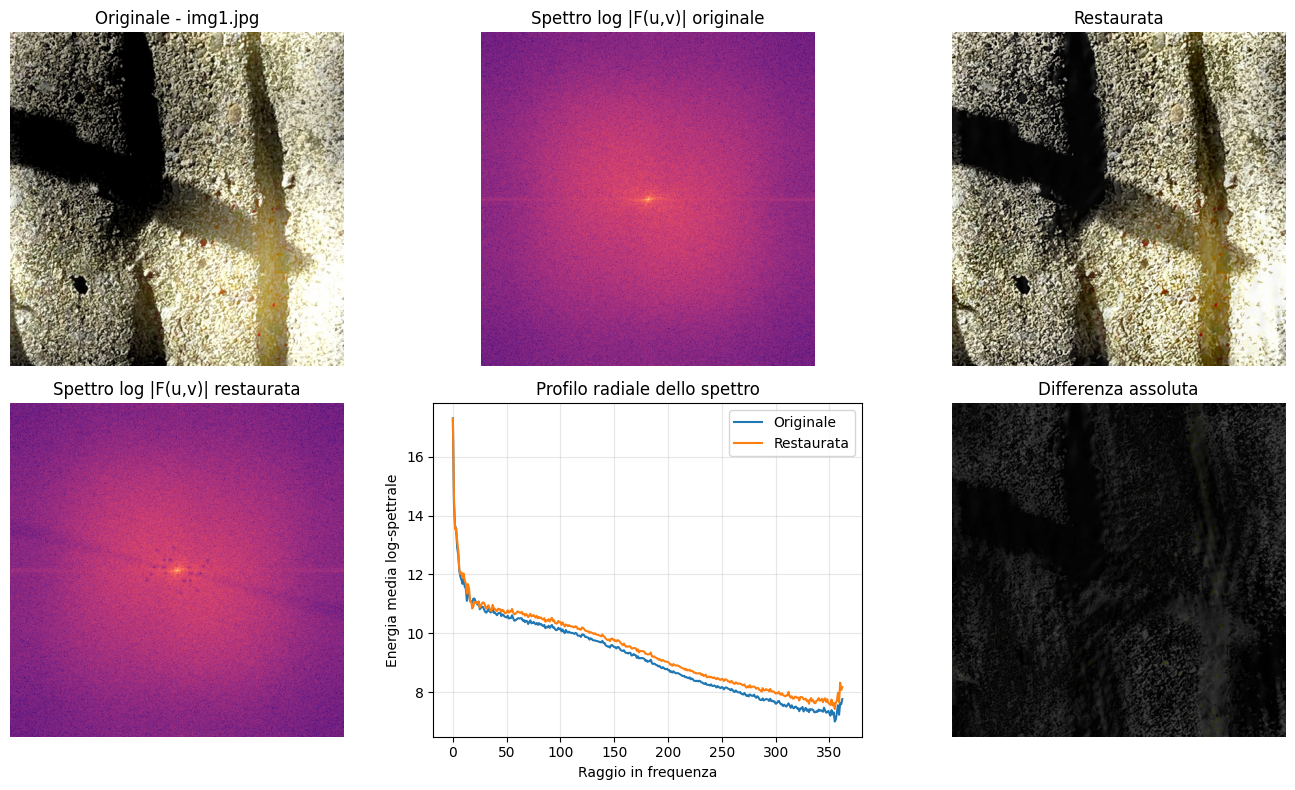

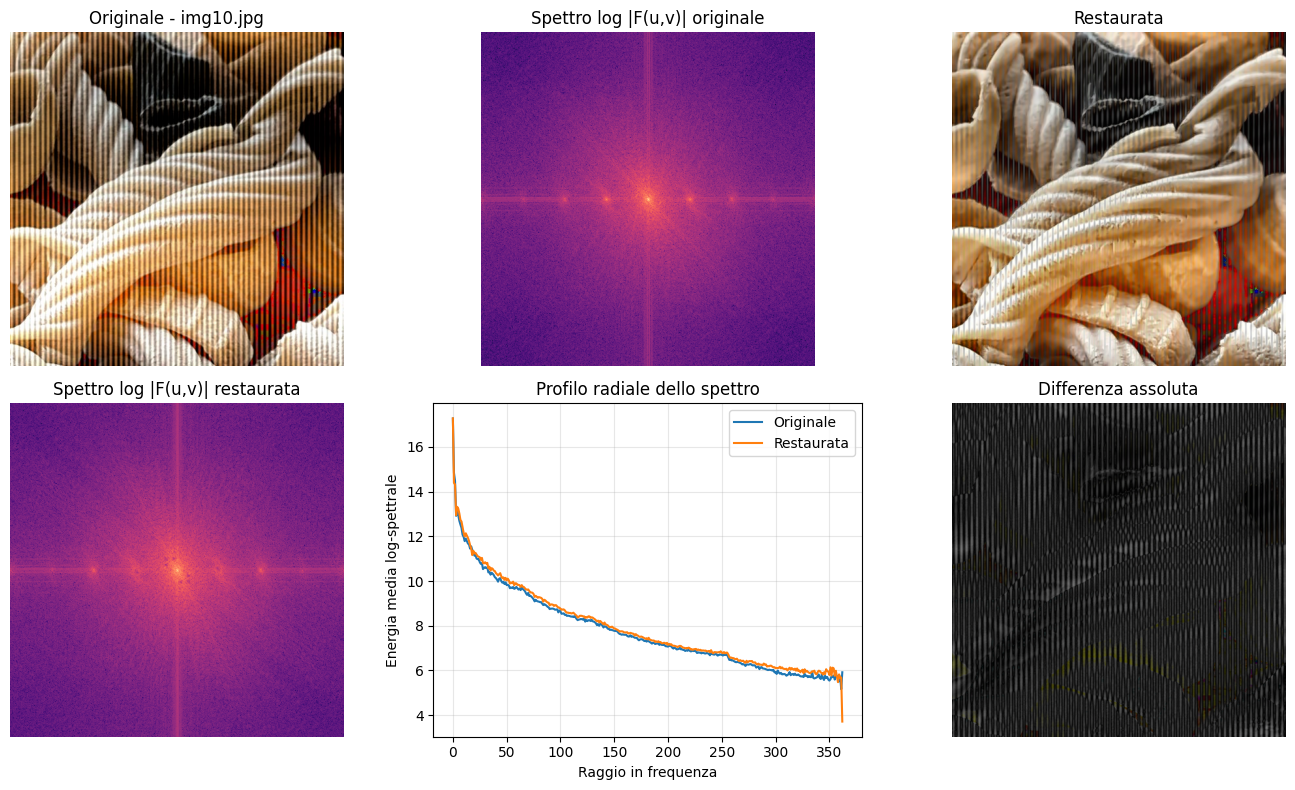

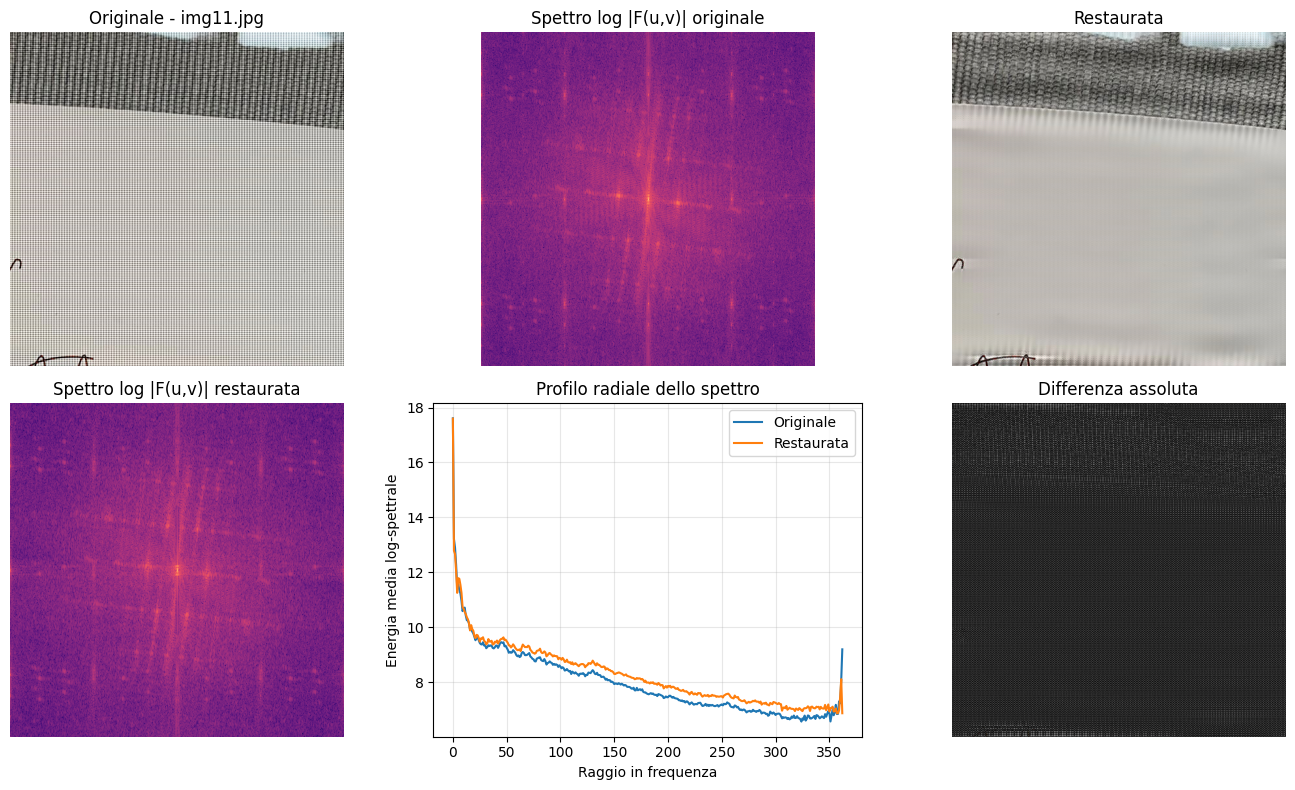

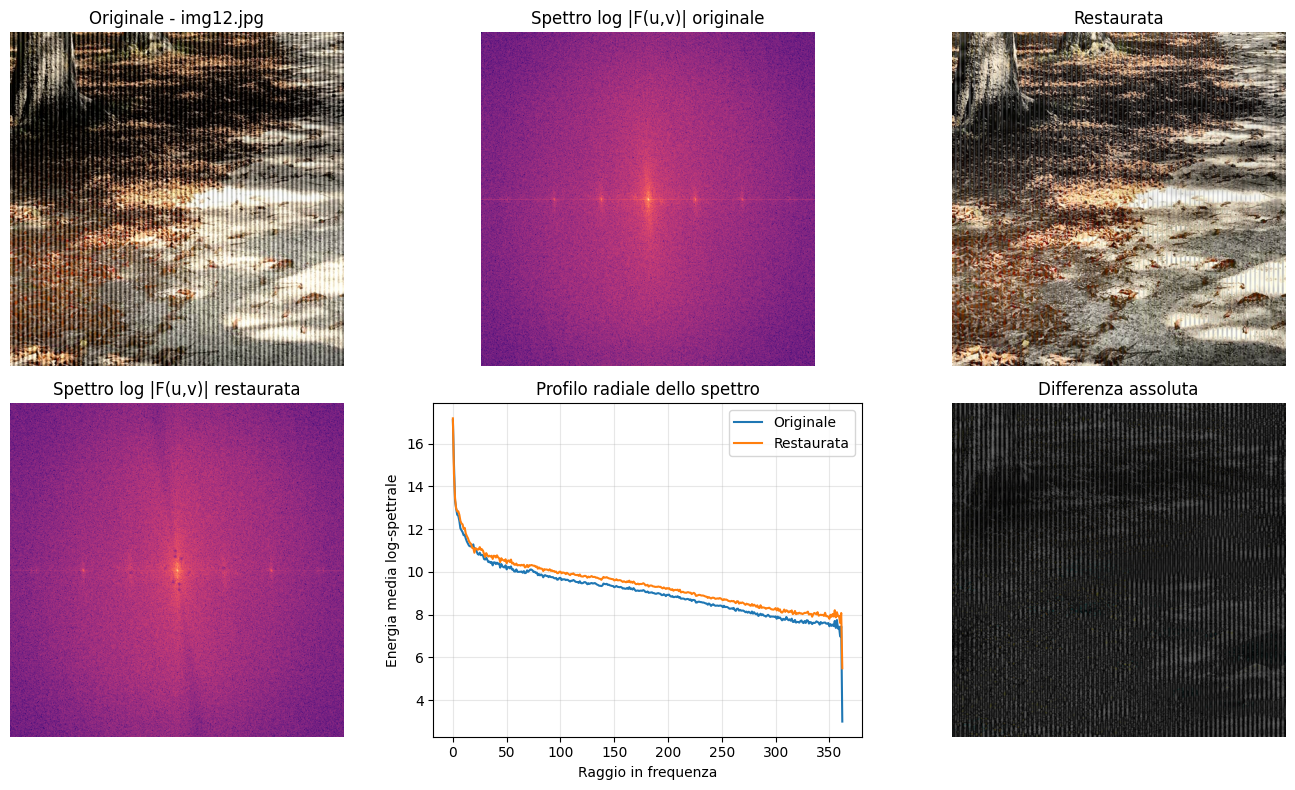

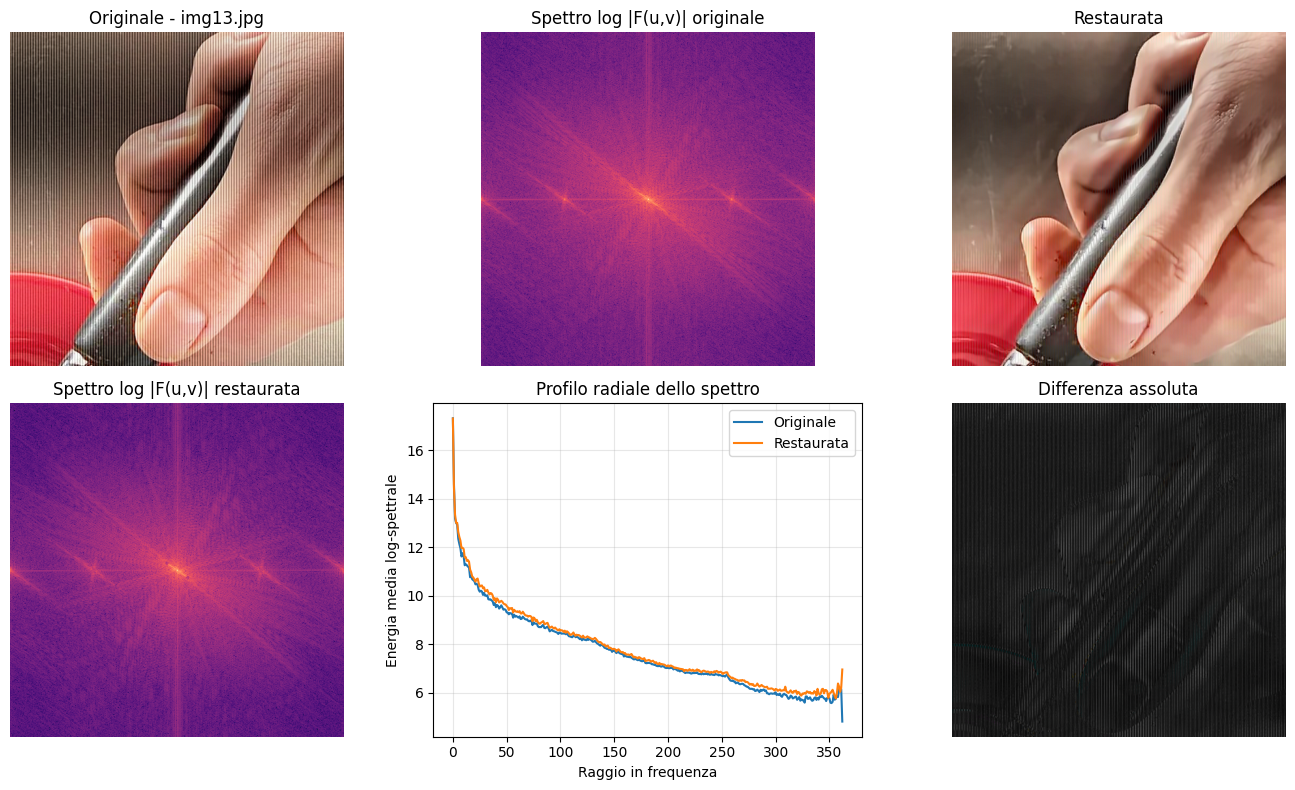

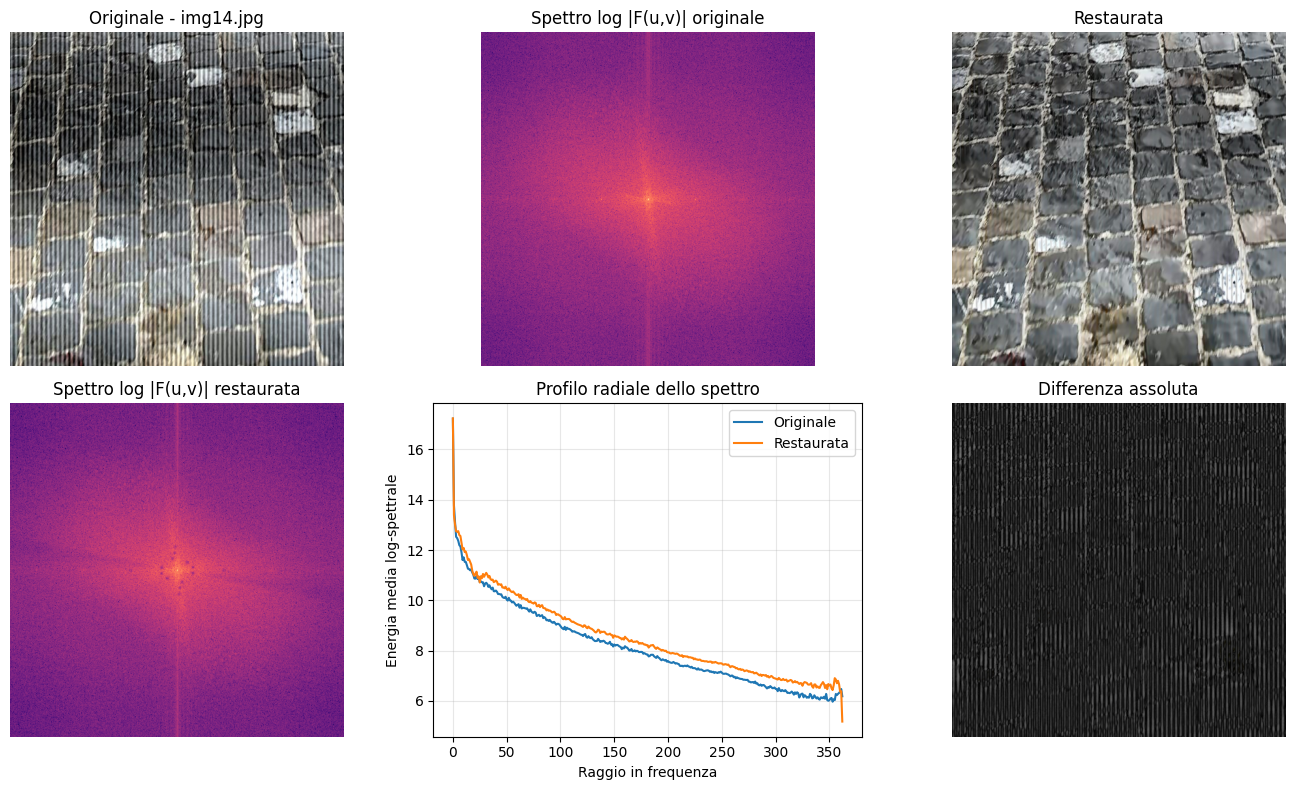

Immagini processate: 15
Cartella immagini restaurate: \\wsl$\Ubuntu\ELIVA\Image_Restoration\restored_images
Cartella analisi spettrale: \\wsl$\Ubuntu\ELIVA\Image_Restoration\spectrum_analysis
Submission salvata in: \\wsl$\Ubuntu\ELIVA\Image_Restoration\submission.csv
Report diagnostico salvato in: \\wsl$\Ubuntu\ELIVA\Image_Restoration\diagnostic_report.csv

Media metriche proxy:
sharpness_before         6586.030
sharpness_after          3106.480
spectrum_mean_before        7.789
spectrum_mean_after         8.003
axis_energy_before          9.644
axis_energy_after           9.807
axis_energy_reduction      -0.163
n_x_peaks                   1.733
n_y_peaks                   1.467
n_offaxis_peaks             9.333
dtype: float64
Riduzione energia su assi (proxy bande) in: 20.0% immagini


In [6]:
# Pipeline completa: analisi Fourier, restauro, salvataggio immagini e submission.csv
RESTORED_DIR = ROOT_DIR / 'restored_images'
SPECTRUM_DIR = ROOT_DIR / 'spectrum_analysis'
RESTORED_DIR.mkdir(parents=True, exist_ok=True)
SPECTRUM_DIR.mkdir(parents=True, exist_ok=True)

solution = {'id': [], 'data': []}
report_rows = []

sample_to_show = min(6, len(image_paths))
sample_paths = set(image_paths[:sample_to_show])

for idx, path in enumerate(image_paths):
    img_name = Path(path).name
    img = cv2.imread(path)
    if img is None:
        print('Skip (non leggibile):', img_name)
        continue

    restored, dbg = restore(img)

    # Salvataggio immagine restaurata in cartella dedicata
    out_path = RESTORED_DIR / img_name
    cv2.imwrite(str(out_path), restored)

    # Costruzione submission.csv con immagini codificate in base64
    solution['id'].append(img_name)
    solution['data'].append(encode_img(restored))

    # Metriche proxy (diagnostiche locali)
    q = quality_proxy(img, restored)
    q['id'] = img_name
    q['n_x_peaks'] = len(dbg['x_peaks'])
    q['n_y_peaks'] = len(dbg['y_peaks'])
    q['n_offaxis_peaks'] = len(dbg['offaxis_peaks'])
    report_rows.append(q)

    # Salva grafico di analisi spettrale per i primi esempi
    if path in sample_paths:
        g0 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
        Fc0 = fft2_centered(g0)
        spec0 = magnitude_spectrum(Fc0)

        g1 = cv2.cvtColor(restored, cv2.COLOR_BGR2GRAY).astype(np.float32)
        Fc1 = fft2_centered(g1)
        spec1 = magnitude_spectrum(Fc1)

        profile0 = radial_profile(spec0)
        profile1 = radial_profile(spec1)

        fig, ax = plt.subplots(2, 3, figsize=(14, 8))
        show_bgr(ax[0, 0], img, f'Originale - {img_name}')
        ax[0, 1].imshow(spec0, cmap='magma')
        ax[0, 1].set_title('Spettro log |F(u,v)| originale')
        ax[0, 1].axis('off')
        show_bgr(ax[0, 2], restored, 'Restaurata')

        ax[1, 0].imshow(spec1, cmap='magma')
        ax[1, 0].set_title('Spettro log |F(u,v)| restaurata')
        ax[1, 0].axis('off')

        ax[1, 1].plot(profile0, label='Originale')
        ax[1, 1].plot(profile1, label='Restaurata')
        ax[1, 1].set_title('Profilo radiale dello spettro')
        ax[1, 1].set_xlabel('Raggio in frequenza')
        ax[1, 1].set_ylabel('Energia media log-spettrale')
        ax[1, 1].legend()
        ax[1, 1].grid(True, alpha=0.3)

        diff = cv2.absdiff(img, restored)
        show_bgr(ax[1, 2], diff, 'Differenza assoluta')

        plt.tight_layout()
        fig.savefig(str(SPECTRUM_DIR / f'{Path(img_name).stem}_analysis.png'), dpi=150)
        plt.show()


# Salvataggio CSV di submission
submission_path = ROOT_DIR / 'submission.csv'
df = pd.DataFrame(solution)
df.to_csv(submission_path, index=False)

# Report diagnostico locale
report_df = pd.DataFrame(report_rows)
report_path = ROOT_DIR / 'diagnostic_report.csv'
report_df.to_csv(report_path, index=False)

print('Immagini processate:', len(df))
print('Cartella immagini restaurate:', RESTORED_DIR)
print('Cartella analisi spettrale:', SPECTRUM_DIR)
print('Submission salvata in:', submission_path)
print('Report diagnostico salvato in:', report_path)

if not report_df.empty:
    print('\nMedia metriche proxy:')
    print(report_df.drop(columns=['id']).mean(numeric_only=True).round(3))

    if 'axis_energy_reduction' in report_df.columns:
        improved = (report_df['axis_energy_reduction'] > 0).mean() * 100
        print(f'Riduzione energia su assi (proxy bande) in: {improved:.1f}% immagini')